In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Bruno\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [4]:
import os
file_path = os.path.join(path, "amz_uk_price_prediction_dataset.csv")
original_df = pd.read_csv(file_path)

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [5]:
df = original_df.copy()

In [6]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [8]:
df.shape

(2443651, 9)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [32]:
df.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [34]:
df.duplicated().sum()

np.int64(0)

In [40]:
crosstab_result = pd.crosstab(df.category, df.isBestSeller)
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [57]:
crosstab_normalized = round(pd.crosstab(df.category, df.isBestSeller, normalize="index"), 2)
crosstab_normalized[True].sort_values(ascending=False)

category
Smart Home Security & Lighting    0.06
Health & Personal Care            0.06
Grocery                           0.06
Power & Hand Tools                0.04
Mobile Phone Accessories          0.04
                                  ... 
Hi-Fi & Home Audio Accessories    0.00
Hi-Fi Receivers & Separates       0.00
Hi-Fi Speakers                    0.00
Hiking Hand & Foot Warmers        0.00
eBook Readers & Accessories       0.00
Name: True, Length: 296, dtype: float64

The results indicate that there is not categories where being a best-seller is more prevalent.

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [64]:
crosstab_result.columns

Index([False, True], dtype='bool', name='isBestSeller')

In [66]:
crosstab_result.index

Index(['3D Printers', '3D Printing & Scanning',
       'Abrasive & Finishing Products', 'Action Cameras', 'Adapters',
       'Agricultural Equipment & Supplies', 'Alexa Built-In Devices',
       'Art & Craft Supplies', 'Arts & Crafts', 'Baby',
       ...
       'Uninterruptible Power Supply Units & Accessories',
       'Vacuums & Floorcare', 'Vases', 'Water Coolers, Filters & Cartridges',
       'Wearable Technology', 'Wind Instruments', 'Window Treatments', 'Women',
       'Women's Sports & Outdoor Shoes', 'eBook Readers & Accessories'],
      dtype='object', name='category', length=296)

In [71]:
crosstab_result_true = crosstab_result[True]
crosstab_result_true = crosstab_result_true.sort_values(ascending=False)
crosstab_result_true

category
Grocery                        556
Health & Personal Care         552
Baby                           341
Sports & Outdoors              330
Power & Hand Tools             306
                              ... 
Downhill Ski Boots               0
Digital Frames                   0
Motorbike Chassis                0
Motorbike Drive & Gears          0
eBook Readers & Accessories      0
Name: True, Length: 296, dtype: int64

In [37]:
from scipy.stats import chi2_contingency

In [80]:
_, chi2_pvalue, _, _  = chi2_contingency(crosstab_result)
round(chi2_pvalue, 10)

if chi2_pvalue < 0.05:
    print(f"The p-value is {float(chi2_pvalue)} and the null hypothesis can be rejected.")
else:
    print(f"The p-value is {float(chi2_pvalue)} and the null hypothesis can't be rejected.")


The p-value is 0.0 and the null hypothesis can be rejected.


The null-hypothesis states that the two categorical variables category and isBestSeller are independent.
The obtained chi-square p-values is < 0.05, indicating the null hypothesis can be rejected and we can confirm the two variables are dependent.

In [50]:
from scipy.stats.contingency import association

In [74]:
round(association(crosstab_result, method='cramer'), 2)

0.12

With a Cramér's V result of 0.12, we can conclude that there is a weak association between the two variables category and isBestSeller.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [ ]:
crosstab_result_ordered = crosstab_result.sort_values(by=True, ascending=False)
crosstab_result_ordered

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
...,...,...
Downhill Ski Boots,1284,0
Digital Frames,774,0
Motorbike Chassis,107,0


In [91]:
crosstab_top_result = crosstab_result_ordered.iloc[0:20]
crosstab_top_result

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
Beauty,19010,302
Pet Supplies,9152,285
Arts & Crafts,9319,230
Women,17559,213


In [93]:
crosstab_top_result.shape

(20, 2)

Considering the dataset has 296 rows, it would not be feasible to show all bars in one graph, so the top-20 categories with the most True values were selected.

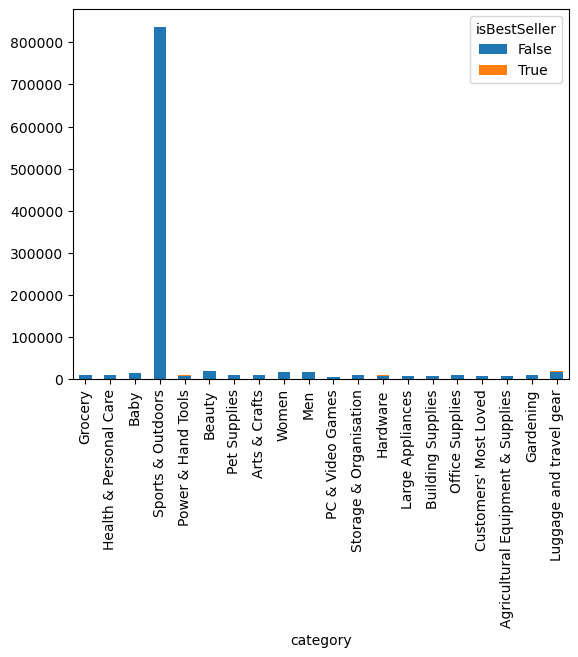

In [92]:
crosstab_top_result.plot(kind='bar', stacked=True)
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [94]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [109]:
q1 = np.quantile(df["price"], 0.25)
q3 = np.quantile(df["price"], 0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

df_no_outliers = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]
df_no_outliers.reset_index(drop=True, inplace=True)
df_no_outliers


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2115958,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2115959,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2115960,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2115961,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

In [124]:
top_20_categories = df_no_outliers['category'].value_counts().head(20).index
top_20_categories

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor',
       'Luggage and travel gear', 'Women', 'Fragrances',
       'Handmade Kitchen & Dining', 'Handmade Artwork',
       'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men',
       'Baby'],
      dtype='object', name='category')

In [125]:
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top_20_categories)]
df_top20


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
16267,21072,B09477KHQ3,"Personalised Birthday Print Gift ""THE YEAR YOU...",4.5,763,7.99,False,900,Handmade Home & Kitchen Products
16268,21073,B0BSRFQYG8,Wax Melts 4 Bars | Build Your Own Box (Choose ...,3.9,117,6.49,True,800,Handmade Home & Kitchen Products
16269,21074,B09N9GVHV9,"Personalised Birthday Print Gift ""ON THE DAY/Y...",4.6,1155,8.99,True,600,Handmade Home & Kitchen Products
16270,21075,B0BRYGV7PQ,Fresh Wax Melts - Laundry Type Wax Melts - Str...,4.5,56,4.99,True,500,Handmade Home & Kitchen Products
16271,21076,B0B1JHB28R,Manta Makes Work Leaving Gifts | I Used to Wor...,4.7,261,9.95,True,400,Handmade Home & Kitchen Products
...,...,...,...,...,...,...,...,...,...
2103019,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2103020,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2103021,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2110273,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


C:\Users\Bruno\AppData\Local\Temp\ipykernel_17480\1581422532.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x="category", y="price", palette="coolwarm")


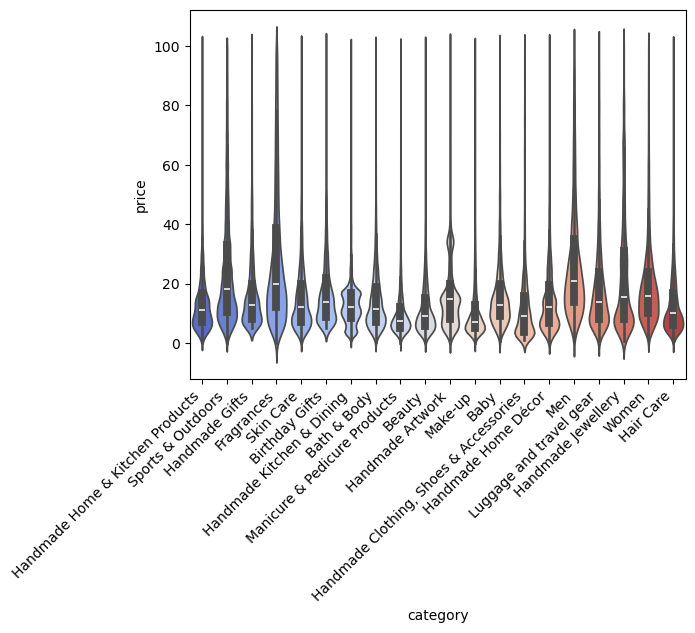

In [139]:
sns.violinplot(data=df_top20, x="category", y="price", palette="coolwarm")
plt.xticks(rotation=45, ha='right')
plt.show()

Out of the top 20 categories based on count, Men listings have the highest median prices, followed by Fragrances.

In [149]:
df_no_outliers[["category", "price"]].groupby("category").agg("median").sort_values(by="price", ascending=False)

,price
category,
Desktop PCs,74.00
Boxing Shoes,69.79
Tablets,69.00
Graphics Cards,68.54
Motherboards,67.92
...,...
Adapters,7.05
Make-up,7.00
Signs & Plaques,6.99


The category Desktop PCs tend to have the highest median price, followed by Boxing Shoes and Tablets.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

In [135]:
top_10_categories = df_no_outliers['category'].value_counts().head(10).index
top_10_categories

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object', name='category')

In [136]:
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]
df_top10


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
73162,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
73163,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
73164,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
73165,89488,B07QDMLMJH,Nextbase Powered Mount Variations For Cameras ...,4.7,1223,19.95,False,0,Sports & Outdoors
73166,89489,B09TQMCNY7,WOLFANG Action Camera GA100 with 64GB microSDX...,4.2,55,49.99,False,0,Sports & Outdoors
...,...,...,...,...,...,...,...,...,...
2103019,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2103020,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2103021,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2110273,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


C:\Users\Bruno\AppData\Local\Temp\ipykernel_17480\852087580.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top10, x="category", y="price", palette="coolwarm", errorbar=None, estimator="mean")


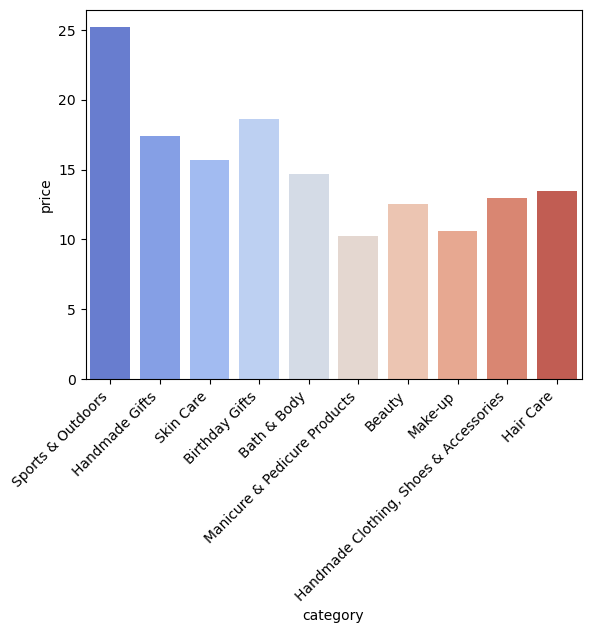

In [140]:
sns.barplot(data=df_top10, x="category", y="price", palette="coolwarm", errorbar=None, estimator="mean")
plt.xticks(rotation=45, ha='right')
plt.show()

Out of the top 10 categories based on count, Sports & Outdoors listings have the highest mean prices, followed by Birthday Gifts and Handmade Gifts.

In [150]:
df_no_outliers[["category", "price"]].groupby("category").agg("mean").sort_values(by="price", ascending=False)

,price
category,
Motherboards,68.772432
Boxing Shoes,67.417803
Desktop PCs,66.915562
Tablets,66.552971
Graphics Cards,65.103509
...,...
Bedding Accessories,8.835220
Adapters,8.750197
Signs & Plaques,8.210513


The category Motherboards commands the highest average price, followd by Boxing Shoes and Desktop PCs.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [151]:
df_top10.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
73162,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
73163,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
73164,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
73165,89488,B07QDMLMJH,Nextbase Powered Mount Variations For Cameras ...,4.7,1223,19.95,False,0,Sports & Outdoors
73166,89489,B09TQMCNY7,WOLFANG Action Camera GA100 with 64GB microSDX...,4.2,55,49.99,False,0,Sports & Outdoors


In [156]:
df_top10.shape

(862465, 9)

C:\Users\Bruno\AppData\Local\Temp\ipykernel_17480\3375780051.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x="category", y="stars", palette="coolwarm", legend=True)


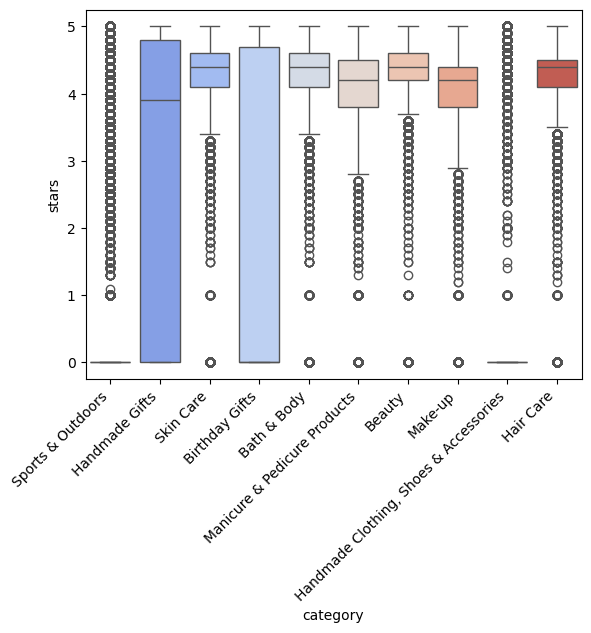

In [155]:
sns.boxplot(data=df_top10, x="category", y="stars", palette="coolwarm", legend=True)
plt.xticks(rotation=45, ha='right')
plt.show()

Categories Skin Care, Bath & Body, Beauty, and Hair Care have the highest median rating. They also show low spread of rating values.
Handmade Gifts and Birthday Gifts show a large spread of ratinhs, with the first showing a higer median than the second.
Sports & Outdoors and Handmade Clothing, SHoes & Accessiories have the boxplot limits around 0, which indicate that most of these items were not rated by the users and, therefore, should not be included in this analysis. The outliers these categories show are the products that were effectively rated.

In [ ]:
df_no_outliers[["category", "stars"]].groupby("category").agg("median").sort_values(by="stars", ascending=False)

,stars
category,
Computer Memory,4.7
Building & Construction Toys,4.6
Office Paper Products,4.6
Luxury Food & Drink,4.6
Kids' Play Figures,4.6
...,...
Hockey Shoes,0.0
Hi-Fi Receivers & Separates,0.0
Handmade Kitchen & Dining,0.0


Computer Memory is the category with the highest median rating, followed by Building & Construction Toys and Office Paper Products.

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

In [164]:
round(float(df_no_outliers["stars"].corr(df_no_outliers["price"], method="pearson")), 2)

-0.08

A Pearson correlation coefficient of -0.08 indicates that there is no linear correlation between price and stars.

In [165]:
round(float(df_no_outliers["stars"].corr(df_no_outliers["price"], method="spearman")), 2)

-0.07

A Pearson correlation coefficient of -0.07 indicates that there is no monotonic correlation between price and stars.

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

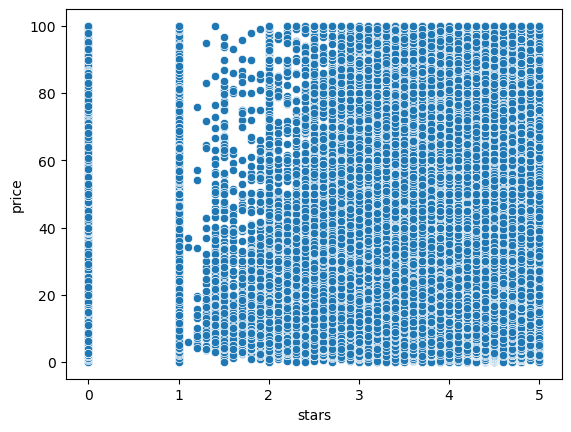

In [166]:
sns.scatterplot(data=df_no_outliers, x='stars', y='price')
plt.show()

No pattern is observed in the relationship between rating and price. However it's possible to observe that there is no listing with a rating between 0 and 1 star.

In [170]:
num = df_no_outliers.select_dtypes(include="number")

In [172]:
num.head()

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0


In [174]:
num.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2115963 entries, 0 to 2115962
Data columns (total 5 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   stars              float64
 2   reviews            int64  
 3   price              float64
 4   boughtInLastMonth  int64  
dtypes: float64(2), int64(3)
memory usage: 80.7 MB


In [171]:
num.corr()

,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,0.030288,0.020236,0.001717,0.017116
stars,0.030288,1.000000,0.083920,-0.077673,0.113994
reviews,0.020236,0.083920,1.000000,-0.008498,0.105624
price,0.001717,-0.077673,-0.008498,1.000000,-0.059051
boughtInLastMonth,0.017116,0.113994,0.105624,-0.059051,1.000000


In [175]:
correlation_matrix = num.corr()

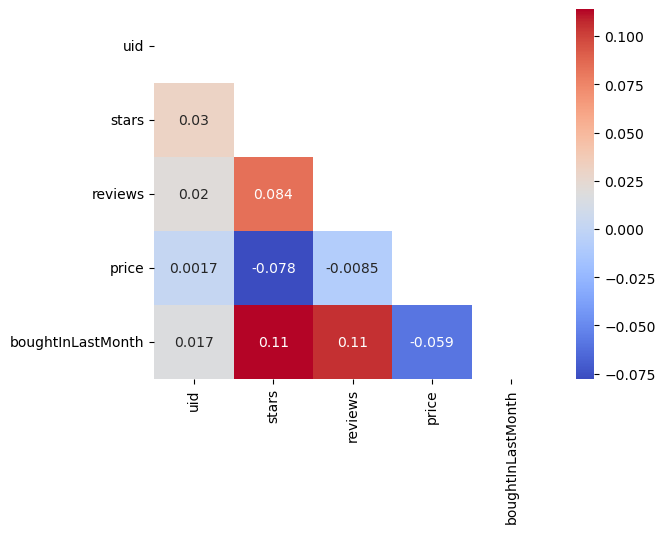

In [177]:
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap="coolwarm")

plt.show()

All numerical variables show poor correlations, either positive or negative.

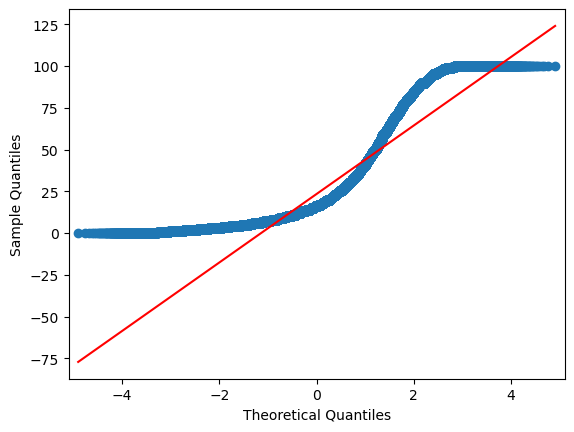

In [180]:
import statsmodels.api as sm

sm.qqplot(df_no_outliers['price'], line='s');
plt.show()

The QQ plot shows a strong deviation from the reference line, indicating that price does not follow a normal distribution.